In [1]:
SEED = 0

In [15]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

data = np.load("../data/learning_set.npz")
series = data["series"] # shape=(3463, 3, 128): 3463 objects; semi-major axis a, eccentricity, drag force term; 128 days
label = data["label"]   # shape=(3463,)
split = data["split"]   # shape=(3463,)

cat = pd.read_csv("../data/catalogue.csv")
for object_id, rows in cat.groupby("object_id"):
    rows = rows.sort_values("epoch_day")
    t, a = rows["epoch_day"].to_numpy(), rows["a_km"].to_numpy()

# Step 1

## 1. 
Count the objects in each split (training, validation, test), and the class frequencies in the training and validation sets. 

Then build a majority-class baseline: a classifier that predicts for every object the class that is most frequent in the training set. 

Evaluate it on the validation set with two metrics:
- The accuracy: the fraction of validation objects whose predicted label is the
label in the file.
- The balanced accuracy: the fraction of correctly predicted objects within
each class, averaged over the four classes.

In [3]:
np.unique(split)

array([0, 1, 2], dtype=int8)

In [4]:
np.unique(label)

array([-1,  0,  1,  2,  3], dtype=int8)

In [7]:
mask = (label == "0") & (split == "0")
matching_labels = label[mask]
np.where(mask)[0]

array([], dtype=int64)

In [12]:
np.sum((label==0)&(split==0))

np.int64(421)

In [14]:
print(f"Number of training objects: {np.count_nonzero(split==0)}")
print(f"\t class 0: {np.sum((label==0)&(split==0))}")
print(f"\t class 1: {np.sum((label==1)&(split==0))}")
print(f"\t class 2: {np.sum((label==2)&(split==0))}")
print(f"\t class 3: {np.sum((label==3)&(split==0))}")
print(f"Number of validation objects: {np.count_nonzero(split==1)}")
print(f"\t class 0: {np.sum((label==0)&(split==1))}")
print(f"\t class 1: {np.sum((label==1)&(split==1))}")
print(f"\t class 2: {np.sum((label==2)&(split==1))}")
print(f"\t class 3: {np.sum((label==3)&(split==1))}")
print(f"Number of test objects: {np.count_nonzero(split==2)}")

Number of training objects: 2077
	 class 0: 421
	 class 1: 455
	 class 2: 595
	 class 3: 606
Number of validation objects: 691
	 class 0: 146
	 class 1: 150
	 class 2: 202
	 class 3: 193
Number of test objects: 695


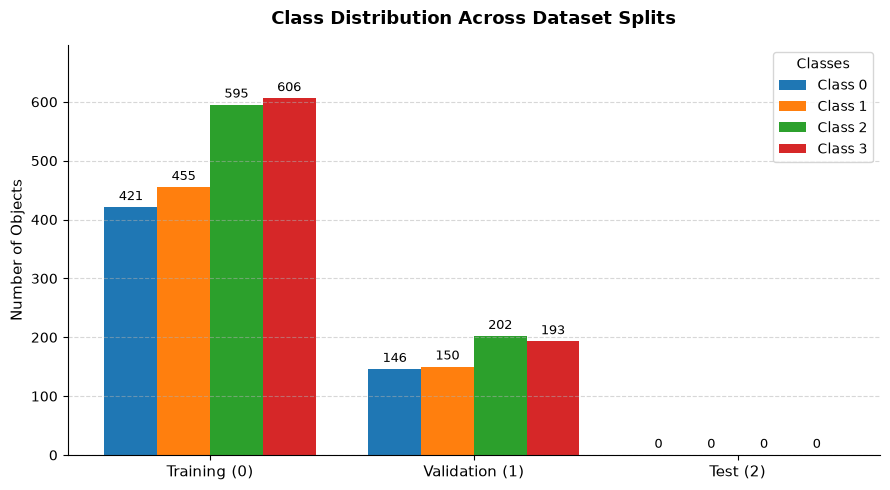

In [16]:
# 1. Compute counts dynamically
splits = [0, 1, 2]
split_names = ['Training (0)', 'Validation (1)', 'Test (2)']
classes = [0, 1, 2, 3]

# Shape: (num_classes, num_splits)
counts = np.array([
    [np.sum((label == c) & (split == s)) for s in splits]
    for c in classes
])

# 2. Plot grouped bar chart
x = np.arange(len(split_names))
width = 0.2  # width of each bar

fig, ax = plt.subplots(figsize=(9, 5))

for i, c in enumerate(classes):
    offset = (i - 1.5) * width
    bars = ax.bar(x + offset, counts[i], width, label=f'Class {c}')
    # Add exact numbers on top of bars
    ax.bar_label(bars, padding=3, fontsize=9)

# 3. Formatting
ax.set_title('Class Distribution Across Dataset Splits', fontsize=13, fontweight='bold', pad=15)
ax.set_ylabel('Number of Objects', fontsize=11)
ax.set_xticks(x)
ax.set_xticklabels(split_names, fontsize=11)
ax.legend(title='Classes')
ax.grid(axis='y', linestyle='--', alpha=0.5)

# Clean up top/right borders and add headroom for bar labels
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)
ax.set_ylim(0, counts.max() * 1.15)

plt.tight_layout()
plt.show()